# Lab 4-2 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab04_2.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [5]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import lab04_2

lab04_2.set_seed()
X, y = lab04_2.load_data('../data/motor_health.csv')
data = lab04_2.prepare_data(X, y)
results = lab04_2.run_experiment(data)

# Re-train the winning configuration to get its per-epoch history.
# Same seed and same data, so this repeats exactly the run that won the search.
best = results['best_config']
lab04_2.set_seed()
best_model = lab04_2.build_model(data['input_dim'], best['hidden_size'])
history = lab04_2.train_model(best_model, data['train_loader'], data['val_loader'], best['lr'])

best, results['val'], results['test']

({'hidden_size': 32, 'lr': 0.1},
 {'loss': 0.335632, 'accuracy': 0.855},
 {'loss': 0.370398, 'accuracy': 0.8475})

## Plot 1 — Learning curves of the selected configuration

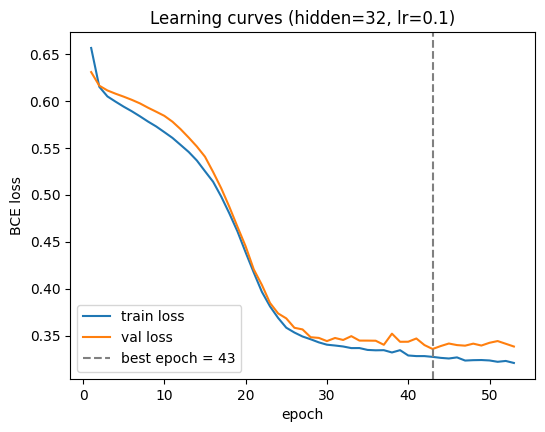

In [6]:
epochs = range(1, len(history['train_loss'])+1)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(epochs, history['train_loss'], label='train loss')
ax.plot(epochs, history['val_loss'], label='val loss')
ax.axvline(history['best_epoch'], linestyle='--', color='gray',
           label=f"best epoch = {history['best_epoch']}")
ax.set_xlabel('epoch')
ax.set_ylabel('BCE loss')
ax.set_title(f"Learning curves (hidden={best['hidden_size']}, lr={best['lr']})")
ax.legend()
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 2 — The grid

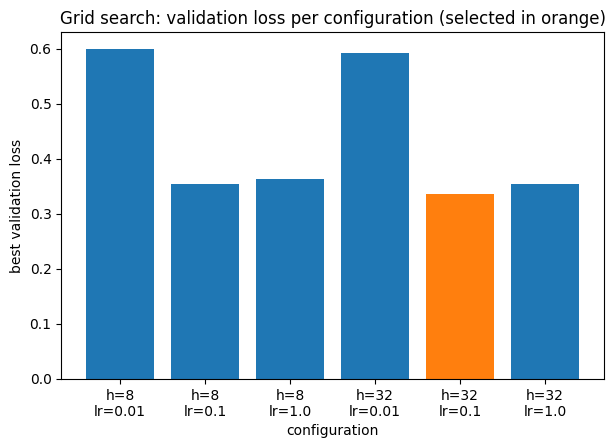

In [3]:
labels = [f"h={g['hidden_size']}\nlr={g['lr']}" for g in results['grid']]
losses = [g['val_loss'] for g in results['grid']]
colors = ['tab:orange' if v == min(losses) else 'tab:blue' for v in losses]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(len(losses)), losses, color=colors)
ax.set_xticks(range(len(losses)))
ax.set_xticklabels(labels)
ax.set_xlabel('configuration')
ax.set_ylabel('best validation loss')
ax.set_title('Grid search: validation loss per configuration (selected in orange)')
plt.savefig('fig2.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 3 — Validation against test

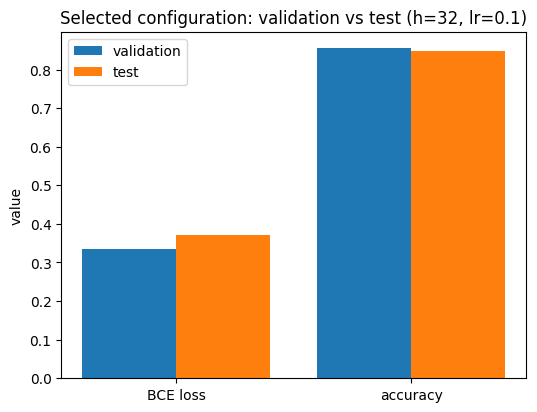

In [4]:
import numpy as np
x = np.arange(2)
val_vals = [results['val']['loss'], results['val']['accuracy']]
test_vals = [results['test']['loss'], results['test']['accuracy']]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(x-0.2, val_vals, width=0.4, label='validation')
ax.bar(x+0.2, test_vals, width=0.4, label='test')
ax.set_xticks(x)
ax.set_xticklabels(['BCE loss', 'accuracy'])
ax.set_ylabel('value')
ax.set_title(f"Selected configuration: validation vs test (h={best['hidden_size']}, lr={best['lr']})")
ax.legend()
plt.savefig('fig3.png', dpi=150, bbox_inches='tight')
plt.show()